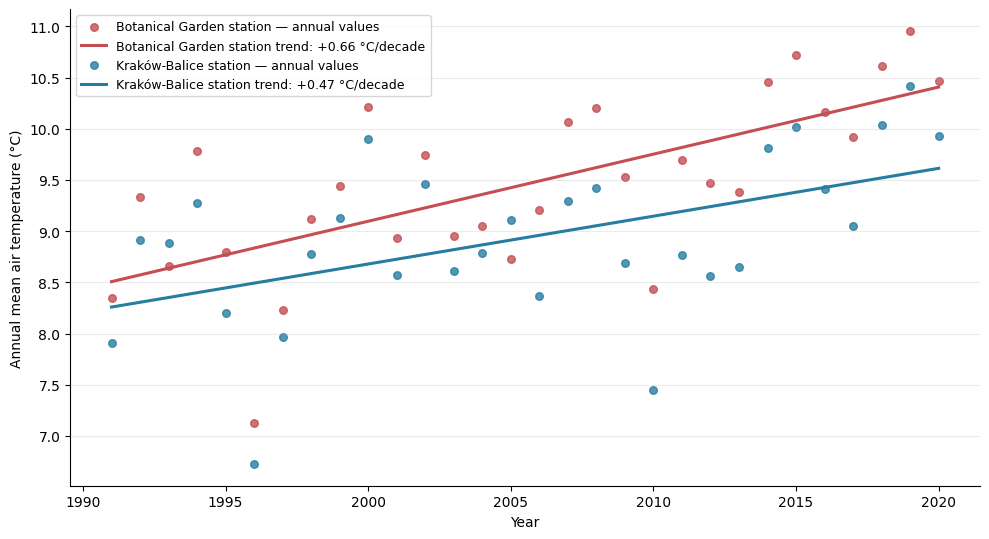

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 1.Excel file
raw = pd.read_excel("dane_surowe_dla_stacji_1.xlsx", header=None)

# 2. Annual mean temperatures
years = pd.to_numeric(raw.iloc[2:32, 1], errors="coerce")

balice = pd.to_numeric(raw.iloc[2:32, 14], errors="coerce")
garden = pd.to_numeric(raw.iloc[2:32, 31], errors="coerce")

# 3. Plot
fig, ax = plt.subplots(figsize=(10, 5.5))

stations = [
    (garden, "Botanical Garden station", "#C44E52"),
    (balice, "Kraków-Balice station", "#277DA1")
]

for values, name, color in stations:
    valid = values.notna() & years.notna()
    x = years[valid].astype(float)
    y = values[valid].astype(float)

    # Annual observations
    ax.scatter(x, y, color=color, s=30, alpha=0.8,
               label=f"{name} — annual values")

    # Linear trend
    result = stats.linregress(x, y)
    trend_x = np.linspace(x.min(), x.max(), 100)
    trend_y = result.intercept + result.slope * trend_x

    ax.plot(
        trend_x, trend_y,
        color=color, linewidth=2.2,
        label=f"{name} trend: {result.slope * 10:+.2f} °C/decade"
    )

# 4. Axis labels
ax.set_xlabel("Year")
ax.set_ylabel("Annual mean air temperature (°C)")

# Y-axis values every 0.5 °C
ax.set_yticks(np.arange(7.0, 11.1, 0.5))

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
ax.legend(fontsize=9, frameon=True)

fig.tight_layout()

# Save the figure
fig.savefig(
    "krakow_temperature_trends.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

